# BME 574 — The architectures, in code
### LeNet-5, VGG, ResNet and U-Net, written out and trained on MNIST

The lecture showed you a table of architectures and two diagrams. This notebook is the same
content as **runnable PyTorch**: every model written from scratch, trained on the same data, and
compared on the same axes.

**Runtime** about eight minutes. Everything trains on a 12,000-image subset of MNIST, which is
plenty to separate these models and keeps the notebook interactive. Accuracy is not the point
here — the code is.

**Self-contained.** It imports nothing local and needs no file beside it.

---

| § | | |
|---|---|---|
| 1 | **LeNet-5, as published** | 1998, and exactly 60,000 parameters |
| 2 | **LeNet-5, as everyone writes it** | and why it has 61,706 |
| 3 | **VGG-style** | 3×3 everywhere, widths doubling |
| 4 | **ResNet-style** | the residual block, written out |
| 5 | **U-Net** | segmentation: a label for every pixel |
| 6 | **The real ones** | torchvision's AlexNet, VGG-16, ResNet-18 side by side |

In [3]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import TensorDataset, DataLoader

plt.rcParams.update({'font.size': 9, 'figure.dpi': 120})
SEED, N_TRAIN, EPOCHS, BATCH, LR = 0, 12000, 3, 128, 1e-3
MNIST_MEAN, MNIST_STD = 0.1307, 0.3081
torch.manual_seed(SEED)

transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize((MNIST_MEAN,), (MNIST_STD,))])
train_dataset = torchvision.datasets.MNIST('./data', train=True, download=True,
                                           transform=transform)
test_dataset = torchvision.datasets.MNIST('./data', train=False, download=True,
                                          transform=transform)

to_t = lambda u8: (((u8.float() / 255.0) - MNIST_MEAN) / MNIST_STD).unsqueeze(1)
Xtr, ytr = to_t(train_dataset.data)[:N_TRAIN], train_dataset.targets[:N_TRAIN].clone()
Xte, yte = to_t(test_dataset.data), test_dataset.targets.clone()

# LeNet-5 wants 32x32: the paper pads the 28x28 field so that stroke endpoints
# can sit at the centre of a top-layer receptive field.
pad32 = lambda X: F.pad(X, (2, 2, 2, 2), value=(0.0 - MNIST_MEAN) / MNIST_STD)
Xtr32, Xte32 = pad32(Xtr), pad32(Xte)

print('train', tuple(Xtr.shape), ' test', tuple(Xte.shape))
print('padded for LeNet-5:', tuple(Xtr32.shape))

train (12000, 1, 28, 28)  test (10000, 1, 28, 28)
padded for LeNet-5: (12000, 1, 32, 32)


In [4]:
def n_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


def accuracy(model, X, y, bs=1000):
    model.eval()
    with torch.no_grad():
        pred = torch.cat([model(X[i:i + bs]).argmax(1) for i in range(0, len(X), bs)])
    return float((pred == y).double().mean())


def train(model, X, y, Xv, yv, epochs=EPOCHS, lr=LR, batch=BATCH, seed=SEED, tag=''):
    loader = DataLoader(TensorDataset(X, y), batch_size=batch, shuffle=True,
                        generator=torch.Generator().manual_seed(seed + 100))
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    lossfn = nn.CrossEntropyLoss()
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        for xb, yb in loader:
            opt.zero_grad()
            lossfn(model(xb), yb).backward()
            opt.step()
    a = accuracy(model, Xv, yv)
    print('%-26s %9s params   test accuracy %.4f   (%.0f s)'
          % (tag, format(n_params(model), ','), a, time.time() - t0))
    return a


RESULTS = {}
print('helpers ready')

helpers ready


---
# 1 · LeNet-5, as published

LeCun, Bottou, Bengio & Haffner, *Proceedings of the IEEE* 86(11), 1998.

Three pieces of it are **not** what a modern reimplementation uses, and each needs its own class:

- **S2 and S4 are not max pooling.** Each unit averages its 2×2 block, multiplies by a *trainable*
  coefficient, adds a *trainable* bias, and applies a sigmoid. Two parameters per feature map.
- **C3 is not fully connected to S2.** Its 16 maps read from hand-chosen *subsets* of S2's 6 maps.
  The paper's stated reason is to break symmetry so the maps learn different things.
- **The output is not a softmax.** Ten Euclidean radial basis function units with fixed prototype
  vectors; the network emits a distance, not a probability.

The activation is a scaled hyperbolic tangent, `A·tanh(S·a)` with `A = 1.7159`.

In [5]:
# Table I of the paper: which S2 maps feed each of C3's 16 maps.
C3_TABLE = [
    [0, 1, 2], [1, 2, 3], [2, 3, 4], [3, 4, 5], [4, 5, 0], [5, 0, 1],
    [0, 1, 2, 3], [1, 2, 3, 4], [2, 3, 4, 5], [3, 4, 5, 0], [4, 5, 0, 1], [5, 0, 1, 2],
    [0, 1, 3, 4], [1, 2, 4, 5], [2, 3, 5, 0],
    [0, 1, 2, 3, 4, 5],
]


class Subsampling(nn.Module):
    # S2 / S4. Average the 2x2 block, scale by a trainable coefficient, add a
    # trainable bias, squash. Two parameters per map -- max pooling has none.
    def __init__(self, n_maps):
        super().__init__()
        self.coeff = nn.Parameter(torch.ones(n_maps))
        self.bias = nn.Parameter(torch.zeros(n_maps))

    def forward(self, x):
        x = F.avg_pool2d(x, 2)
        return torch.sigmoid(x * self.coeff[None, :, None, None]
                             + self.bias[None, :, None, None])


class C3(nn.Module):
    # Partially connected convolution: 60 map-pairs x 25 weights + 16 biases.
    def __init__(self, table=C3_TABLE):
        super().__init__()
        self.table = table
        self.n_pairs = sum(len(t) for t in table)          # 60
        self.weight = nn.Parameter(torch.empty(self.n_pairs, 1, 5, 5))
        self.bias = nn.Parameter(torch.zeros(len(table)))
        nn.init.kaiming_uniform_(self.weight, a=5 ** 0.5)

    def forward(self, x):
        outs, k = [], 0
        for j, srcs in enumerate(self.table):
            w = self.weight[k:k + len(srcs)].transpose(0, 1)   # (1, |srcs|, 5, 5)
            outs.append(F.conv2d(x[:, srcs], w, self.bias[j:j + 1]))
            k += len(srcs)
        return torch.cat(outs, dim=1)


class RBFOutput(nn.Module):
    # Ten Euclidean RBF units with FIXED prototypes. Returns the negative
    # squared distance, which we can hand to CrossEntropyLoss as a logit.
    def __init__(self, in_features=84, n_classes=10, seed=0):
        super().__init__()
        g = torch.Generator().manual_seed(seed)
        proto = torch.randint(0, 2, (n_classes, in_features), generator=g).float() * 2 - 1
        self.register_buffer('prototypes', proto)     # a buffer, so NOT trainable

    def forward(self, x):
        return -((x[:, None, :] - self.prototypes[None]) ** 2).sum(-1)


class LeNet5(nn.Module):
    A, S = 1.7159, 2.0 / 3.0

    def __init__(self):
        super().__init__()
        self.c1 = nn.Conv2d(1, 6, 5)      # 32x32 -> 6 @ 28x28
        self.s2 = Subsampling(6)          #       -> 6 @ 14x14
        self.c3 = C3()                    #       -> 16 @ 10x10
        self.s4 = Subsampling(16)         #       -> 16 @ 5x5
        self.c5 = nn.Conv2d(16, 120, 5)   #       -> 120 @ 1x1
        self.f6 = nn.Linear(120, 84)
        self.out = RBFOutput(84, 10)

    def squash(self, x):
        return self.A * torch.tanh(self.S * x)

    def forward(self, x):
        x = self.squash(self.c1(x))
        x = self.s2(x)
        x = self.squash(self.c3(x))
        x = self.s4(x)
        x = self.squash(self.c5(x))
        x = self.squash(self.f6(x.flatten(1)))
        return self.out(x)


torch.manual_seed(SEED)
lenet = LeNet5()
per_layer = [('C1  conv', lenet.c1), ('S2  subsample', lenet.s2), ('C3  conv', lenet.c3),
             ('S4  subsample', lenet.s4), ('C5  conv', lenet.c5), ('F6  dense', lenet.f6),
             ('Output  RBF', lenet.out)]
print('%-18s %10s' % ('layer', 'parameters'))
print('-' * 30)
for name, mod in per_layer:
    print('%-18s %10s' % (name, format(n_params(mod), ',')))
print('-' * 30)
print('%-18s %10s' % ('TOTAL', format(n_params(lenet), ',')))

assert n_params(lenet) == 60000, n_params(lenet)
assert lenet.c3.n_pairs == 60
print('\nexactly 60,000, and 60 map-pairs in C3 - both as the paper states')

layer              parameters
------------------------------
C1  conv                  156
S2  subsample              12
C3  conv                1,516
S4  subsample              32
C5  conv               48,120
F6  dense              10,164
Output  RBF                 0
------------------------------
TOTAL                  60,000

exactly 60,000, and 60 map-pairs in C3 - both as the paper states


In [4]:
torch.manual_seed(SEED)
RESULTS['LeNet-5 (1998)'] = (n_params(lenet),
                             train(lenet, Xtr32, ytr, Xte32, yte, tag='LeNet-5 as published'))

LeNet-5 as published          60,000 params   test accuracy 0.8592   (14 s)


---
# 2 · LeNet-5, as everyone writes it

Search for a LeNet-5 implementation and this is what you get: max pooling, ReLU, a fully connected
C3, and a softmax head. It is a perfectly good small CNN. It is **not** the network in the paper,
and the parameter count gives it away.

In [6]:
def lenet5_modern():
    return nn.Sequential(
        nn.Conv2d(1, 6, 5), nn.ReLU(), nn.MaxPool2d(2),     # max pool, not subsampling
        nn.Conv2d(6, 16, 5), nn.ReLU(), nn.MaxPool2d(2),    # fully connected 6 -> 16
        nn.Flatten(),
        nn.Linear(16 * 5 * 5, 120), nn.ReLU(),
        nn.Linear(120, 84), nn.ReLU(),
        nn.Linear(84, 10))                                   # a real linear head


torch.manual_seed(SEED)
modern = lenet5_modern()
RESULTS['LeNet-5 (modern)'] = (n_params(modern),
                               train(modern, Xtr32, ytr, Xte32, yte, tag='LeNet-5 as written today'))
print()
print('%-26s %s' % ('as published', format(n_params(lenet), ',')))
print('%-26s %s' % ('as written today', format(n_params(modern), ',')))
print('%-26s %s' % ('difference', format(n_params(modern) - n_params(lenet), ',')))
print()
print('Where it comes from: C3 fully connected is 2,416 instead of 1,516 (+900);')
print('max pooling has no parameters where S2 and S4 had 12 and 32 (-44);')
print('and the linear output head has 850 where the fixed RBF units had 0.')
assert n_params(modern) == 61706

LeNet-5 as written today      61,706 params   test accuracy 0.9612   (7 s)

as published               60,000
as written today           61,706
difference                 1,706

Where it comes from: C3 fully connected is 2,416 instead of 1,516 (+900);
max pooling has no parameters where S2 and S4 had 12 and 32 (-44);
and the linear output head has 850 where the fixed RBF units had 0.


### Why the 1998 network scores lower here

It is not that the architecture is worse — the shape of it is still what everyone builds. It is
the **training details**, and they are exactly the things that changed between 1998 and 2012:

- Every sigmoid and tanh **saturates**. Once a unit's input is large the gradient through it is
  nearly zero, so learning stalls. ReLU has gradient 1 wherever it is active, which is most of why
  it replaced them.
- There are **two sigmoids per downsampling layer** here, on the path everything flows through.
- The RBF output with fixed prototypes gives a weaker, less direct training signal than a linear
  layer with cross-entropy.
- And the paper did not use Adam — it used stochastic diagonal Levenberg–Marquardt, with a
  carefully designed schedule, for twenty passes over the data. We gave it three.

Give it more epochs and it closes most of the gap. The lesson is that **the architectural ideas
survived and the optimisation details did not**, which is worth remembering when you read any
paper older than about 2015.

---
# 3 · VGG-style: 3×3 everywhere

The VGG recipe is a rule rather than an architecture: **every convolution is 3×3, stack two or
three of them, pool, double the width, repeat.** Two 3×3 convolutions see a 5×5 patch with 18C²
weights where one 5×5 layer would need 25C², and they put two non-linearities in the path instead
of one.

This is a miniature of VGG-16 scaled for 28×28 — same rule, three stages instead of five.

In [6]:
def vgg_block(c_in, c_out, n_conv=2):
    layers = []
    for i in range(n_conv):
        layers += [nn.Conv2d(c_in if i == 0 else c_out, c_out, 3, padding=1),
                   nn.BatchNorm2d(c_out), nn.ReLU()]
    layers.append(nn.MaxPool2d(2))
    return layers


def vgg_small(widths=(16, 32, 64), n_classes=10):
    layers, c_in = [], 1
    for w in widths:
        layers += vgg_block(c_in, w)
        c_in = w
    layers += [nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(c_in, n_classes)]
    return nn.Sequential(*layers)


torch.manual_seed(SEED)
vgg = vgg_small()
print(vgg)
print()
RESULTS['VGG-style'] = (n_params(vgg), train(vgg, Xtr, ytr, Xte, yte, tag='VGG-style'))
print()
print('Note the head: AdaptiveAvgPool2d(1) collapses each channel to one number, so the')
print('classifier is Linear(%d, 10) = %s weights. Flattening 64x3x3 instead would have'
      % (64, format(64 * 10 + 10, ',')))
print('made it Linear(576, 10). That is why VGG-16 is 89% dense weights and ResNet-18 is 4%.')

Sequential(
  (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (5): ReLU()
  (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (7): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (9): ReLU()
  (10): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (12): ReLU()
  (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (14): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (15):

VGG-style                     72,890 params   test accuracy 0.9846   (18 s)

Note the head: AdaptiveAvgPool2d(1) collapses each channel to one number, so the
classifier is Linear(64, 10) = 650 weights. Flattening 64x3x3 instead would have
made it Linear(576, 10). That is why VGG-16 is 89% dense weights and ResNet-18 is 4%.


---
# 4 · ResNet-style: the residual block

The block computes `y = ReLU(F(x) + x)`. The skip is what makes depth trainable: to pass `x`
through unchanged the block only has to drive `F(x)` to zero, which is easy. Without it, a deep
plain stack has to *learn* the identity in every layer it does not need, and empirically it fails
to — the training error gets worse, which is an optimisation failure rather than overfitting.

One detail worth seeing in code: when the block changes the number of channels or the stride, `x`
and `F(x)` no longer have the same shape, so the skip needs a **1×1 convolution** to match them.
Those are the extra `Conv2d` modules you find when you count the layers of a ResNet yourself.

In [7]:
class BasicBlock(nn.Module):
    def __init__(self, c_in, c_out, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)
        # the skip has to match shapes; identity when it already does
        self.skip = nn.Identity()
        if stride != 1 or c_in != c_out:
            self.skip = nn.Sequential(
                nn.Conv2d(c_in, c_out, 1, stride=stride, bias=False),
                nn.BatchNorm2d(c_out))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.skip(x))          # <- y = F(x) + x


def resnet_small(widths=(16, 32, 64), blocks_per_stage=2, n_classes=10):
    layers = [nn.Conv2d(1, widths[0], 3, padding=1, bias=False),
              nn.BatchNorm2d(widths[0]), nn.ReLU()]
    c_in = widths[0]
    for i, w in enumerate(widths):
        for b in range(blocks_per_stage):
            layers.append(BasicBlock(c_in, w, stride=2 if (b == 0 and i > 0) else 1))
            c_in = w
    layers += [nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(c_in, n_classes)]
    return nn.Sequential(*layers)


torch.manual_seed(SEED)
res = resnet_small()
n_conv = sum(1 for m in res.modules() if isinstance(m, nn.Conv2d))
n_1x1 = sum(1 for m in res.modules() if isinstance(m, nn.Conv2d) and m.kernel_size == (1, 1))
print('%d Conv2d modules, of which %d are 1x1 projections in skip paths' % (n_conv, n_1x1))
print()
RESULTS['ResNet-style'] = (n_params(res), train(res, Xtr, ytr, Xte, yte, tag='ResNet-style'))

15 Conv2d modules, of which 2 are 1x1 projections in skip paths

ResNet-style                 174,970 params   test accuracy 0.9624   (96 s)


In [8]:
# Does the skip actually matter? Same depth, same widths, skip removed.
class PlainBlock(nn.Module):
    def __init__(self, c_in, c_out, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        return F.relu(self.bn2(self.conv2(out)))     # no + x


def plain_small(widths=(16, 32, 64), blocks_per_stage=2, n_classes=10):
    layers = [nn.Conv2d(1, widths[0], 3, padding=1, bias=False),
              nn.BatchNorm2d(widths[0]), nn.ReLU()]
    c_in = widths[0]
    for i, w in enumerate(widths):
        for b in range(blocks_per_stage):
            layers.append(PlainBlock(c_in, w, stride=2 if (b == 0 and i > 0) else 1))
            c_in = w
    layers += [nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(c_in, n_classes)]
    return nn.Sequential(*layers)


torch.manual_seed(SEED)
plain = plain_small()
a_plain = train(plain, Xtr, ytr, Xte, yte, tag='same depth, no skips')
print()
print('residual %.4f   vs   plain %.4f   ->  %+.4f'
      % (RESULTS['ResNet-style'][1], a_plain, RESULTS['ResNet-style'][1] - a_plain))
print()
print('At six blocks the gap is small - the degradation problem the paper describes')
print('shows up past roughly twenty layers. The point of running it here is that the')
print('skip costs you almost nothing when it is not needed.')

same depth, no skips         172,218 params   test accuracy 0.9624   (39 s)

residual 0.9712   vs   plain 0.9624   ->  +0.0088

At six blocks the gap is small - the degradation problem the paper describes
shows up past roughly twenty layers. The point of running it here is that the
skip costs you almost nothing when it is not needed.


---
# 5 · U-Net: a label for every pixel

Everything above answers "what is in this image?". U-Net answers "**what is at each pixel?**",
which is what you want for lesions, volumes and cell counts.

To run it on MNIST we need a segmentation task, so here is an honest toy one: **separate the
digit from the background.** The target mask is just `pixel > 0.5` on the original image — which
means this particular task is nearly trivial. That is fine; the point is the architecture and the
shapes, not the difficulty.

Two deviations from the 2015 paper, both deliberate and both worth knowing:

- The paper uses **unpadded** convolutions, so a 572×572 tile comes out 388×388 and the encoder
  features have to be **cropped** before concatenation. We use `padding=1` so sizes match, which
  is what essentially every modern U-Net does.
- The paper has **no BatchNorm** — it predates its routine use. We include it.

In [9]:
def double_conv(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
        nn.Conv2d(c_out, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU())


class UNet(nn.Module):
    def __init__(self, c_in=1, n_classes=2, widths=(16, 32, 64)):
        super().__init__()
        w0, w1, w2 = widths
        self.enc1 = double_conv(c_in, w0)                 # 28x28
        self.enc2 = double_conv(w0, w1)                   # 14x14
        self.bottleneck = double_conv(w1, w2)             #  7x7
        self.pool = nn.MaxPool2d(2)
        self.up2 = nn.ConvTranspose2d(w2, w1, 2, stride=2)   # 7 -> 14, halves channels
        self.dec2 = double_conv(w1 * 2, w1)                  # *2 because of the concat
        self.up1 = nn.ConvTranspose2d(w1, w0, 2, stride=2)   # 14 -> 28
        self.dec1 = double_conv(w0 * 2, w0)
        self.head = nn.Conv2d(w0, n_classes, 1)              # 1x1 conv to the classes

    def forward(self, x):
        e1 = self.enc1(x)                     # (N, 16, 28, 28)
        e2 = self.enc2(self.pool(e1))         # (N, 32, 14, 14)
        b = self.bottleneck(self.pool(e2))    # (N, 64,  7,  7)
        d2 = self.dec2(torch.cat([self.up2(b), e2], dim=1))   # CONCATENATE, not add
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.head(d1)                  # (N, 2, 28, 28)


torch.manual_seed(SEED)
unet = UNet()
print('%s parameters' % format(n_params(unet), ','))
with torch.no_grad():
    print('input %s -> output %s   (one prediction per pixel)'
          % (tuple(Xtr[:2].shape), tuple(unet(Xtr[:2]).shape)))

117,410 parameters
input (2, 1, 28, 28) -> output (2, 2, 28, 28)   (one prediction per pixel)


In [10]:
# the segmentation targets: is this pixel part of the digit?
raw_tr = train_dataset.data[:N_TRAIN].float() / 255.0
raw_te = test_dataset.data.float() / 255.0
Mtr = (raw_tr > 0.5).long()
Mte = (raw_te > 0.5).long()
print('mask shape', tuple(Mtr.shape), ' foreground fraction %.3f' % Mtr.float().mean())

loader = DataLoader(TensorDataset(Xtr, Mtr), batch_size=BATCH, shuffle=True,
                    generator=torch.Generator().manual_seed(SEED))
opt = torch.optim.Adam(unet.parameters(), lr=1e-3)
lossfn = nn.CrossEntropyLoss()         # per-pixel cross-entropy
t0 = time.time()
for ep in range(2):
    unet.train()
    for xb, mb in loader:
        opt.zero_grad()
        lossfn(unet(xb), mb).backward()    # logits (N,2,28,28) vs targets (N,28,28)
        opt.step()
unet.eval()
with torch.no_grad():
    pred = torch.cat([unet(Xte[i:i + 1000]).argmax(1) for i in range(0, 4000, 1000)])
pix = float((pred == Mte[:4000]).double().mean())
inter = ((pred == 1) & (Mte[:4000] == 1)).sum().item()
union = ((pred == 1) | (Mte[:4000] == 1)).sum().item()
print('pixel accuracy %.4f   IoU on the digit %.4f   (%.0f s)'
      % (pix, inter / union, time.time() - t0))

mask shape (12000, 28, 28)  foreground fraction 0.133


pixel accuracy 0.9957   IoU on the digit 0.9665   (28 s)


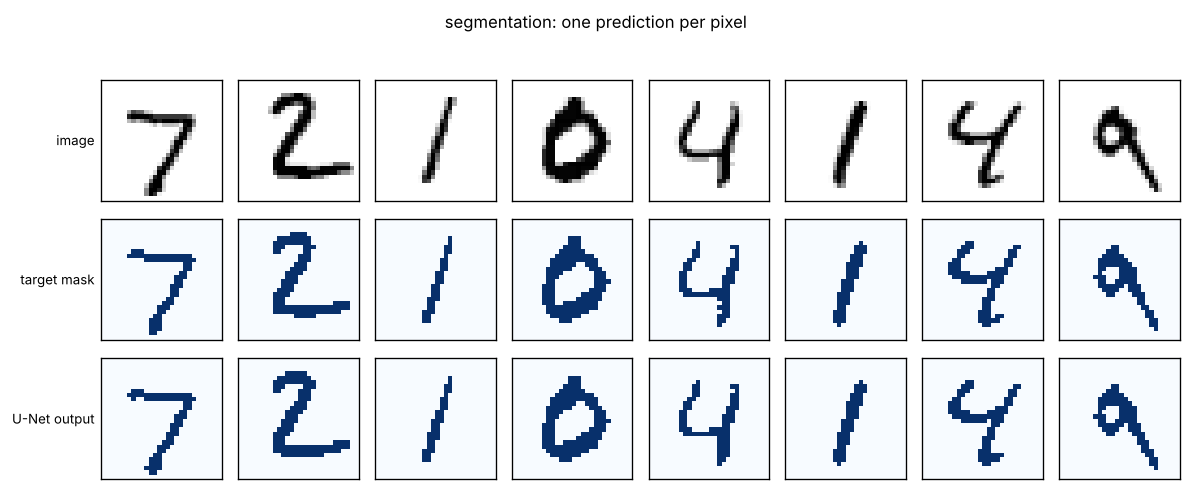

In [11]:
fig, ax = plt.subplots(3, 8, figsize=(10, 4.0))
for j in range(8):
    ax[0, j].imshow(raw_te[j], cmap='gray_r')
    ax[1, j].imshow(Mte[j], cmap='Blues')
    ax[2, j].imshow(pred[j], cmap='Blues')
    for r in range(3):
        ax[r, j].set_xticks([]); ax[r, j].set_yticks([])
for r, lab in enumerate(['image', 'target mask', 'U-Net output']):
    ax[r, 0].set_ylabel(lab, fontsize=8, rotation=0, ha='right', va='center')
fig.suptitle('segmentation: one prediction per pixel', y=1.02, fontsize=10)
plt.tight_layout(); plt.show()

---
# 6 · The real ones

Everything above is scaled for 28×28. Here are the actual ImageNet architectures as torchvision
builds them — no training, just the shapes and the counts. Note the last column.

In [12]:
import torchvision.models as models

rows = []
for name, ctor in (('AlexNet', models.alexnet), ('VGG-16', models.vgg16),
                   ('ResNet-18', models.resnet18), ('ResNet-50', models.resnet50)):
    m = ctor()                                  # random weights; we only want the structure
    conv = [mod for mod in m.modules() if isinstance(mod, nn.Conv2d)]
    lin = [mod for mod in m.modules() if isinstance(mod, nn.Linear)]
    fc_p = sum(p.numel() for mod in lin for p in mod.parameters())
    rows.append((name, len(conv), len(lin),
                 sorted({c.kernel_size[0] for c in conv}),
                 n_params(m), 100 * fc_p / n_params(m)))

print('%-11s %6s %5s %-18s %14s %10s'
      % ('model', 'conv', 'fc', 'kernel sizes', 'parameters', 'in the head'))
print('-' * 72)
for r in rows:
    print('%-11s %6d %5d %-18s %14s %9.1f%%'
          % (r[0], r[1], r[2], 'x'.join(map(str, r[3])) if len(r[3]) > 1
             else '%dx%d' % (r[3][0], r[3][0]), format(r[4], ','), r[5]))
print()
print('VGG-16 has twelve times the parameters of ResNet-18 and performs worse.')
print('Almost all of the difference is the dense head that ResNet does not have.')

model         conv    fc kernel sizes           parameters in the head
------------------------------------------------------------------------
AlexNet          5     3 3x5x11                 61,100,840      96.0%
VGG-16          13     3 3x3                   138,357,544      89.4%
ResNet-18       20     1 1x3x7                  11,689,512       4.4%
ResNet-50       53     1 1x3x7                  25,557,032       8.0%

VGG-16 has twelve times the parameters of ResNet-18 and performs worse.
Almost all of the difference is the dense head that ResNet does not have.


In [13]:
print(models.resnet18().layer1)      # two BasicBlocks, exactly as written in §4

Sequential(
  (0): BasicBlock(
    (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
  (1): BasicBlock(
    (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
)


---
# Summary

model (trained here)      parameters   accuracy
------------------------------------------------
LeNet-5 (1998)                60,000     0.8592
LeNet-5 (modern)              61,706     0.9606
VGG-style                     72,890     0.9846
ResNet-style                 174,970     0.9712

All trained on 12000 images for 3 epochs - these numbers compare architectures
to each other, not to the state of the art.


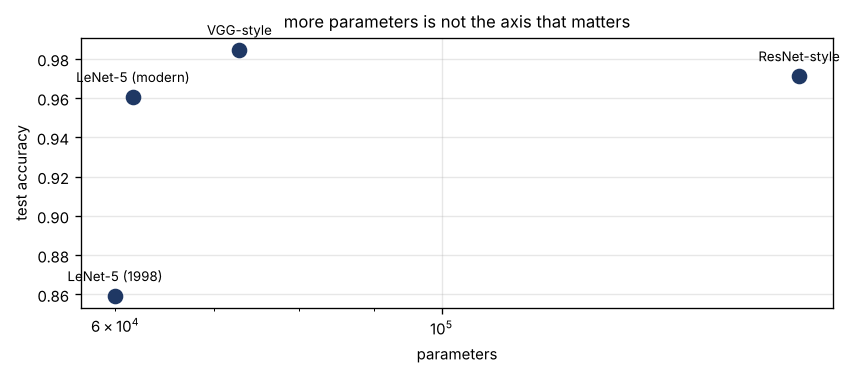

In [14]:
print('%-24s %11s %10s' % ('model (trained here)', 'parameters', 'accuracy'))
print('-' * 48)
for k, (p, a) in RESULTS.items():
    print('%-24s %11s %10.4f' % (k, format(p, ','), a))
print()
print('All trained on %d images for %d epochs - these numbers compare architectures'
      % (N_TRAIN, EPOCHS))
print('to each other, not to the state of the art.')

fig, ax = plt.subplots(figsize=(7.2, 3.2))
ks = list(RESULTS)
ax.scatter([RESULTS[k][0] for k in ks], [RESULTS[k][1] for k in ks],
           s=70, color='#1F3864', zorder=3)
for k in ks:
    ax.annotate(k, (RESULTS[k][0], RESULTS[k][1]), fontsize=8,
                xytext=(0, 9), textcoords='offset points', ha='center')
ax.set_xscale('log'); ax.set_xlabel('parameters'); ax.set_ylabel('test accuracy')
ax.grid(alpha=.3); ax.set_title('more parameters is not the axis that matters', fontsize=10)
plt.tight_layout(); plt.show()

### What to take away

| | |
|---|---|
| **LeNet-5** | the shape of every CNN since: conv, downsample, conv, downsample, classify |
| **VGG** | a *rule* — 3×3, stack, pool, double the width — not an architecture |
| **ResNet** | `y = F(x) + x` makes depth trainable, and global average pooling makes the head small |
| **U-Net** | encoder–decoder with **concatenating** skips, for a label at every pixel |

Next: `BME574_L5_transfer.ipynb`, which takes a trained backbone and moves it to a new task.